# 금 가격 예측 모델 — 훈련기간 고정 vs 유동 비교

목적: 현재 `notebooks/gold_simulation_raw_model.ipynb`(원본) 기준 TVP 모델의 훈련기간이
`TRAIN_START="2016Q1"`, `TRAIN_END="2023Q4"`로 하드코딩되어 있는데, 이걸 예측시점 직전
분기까지 유동적으로 늘렸을 때 출력값(예측가)이 얼마나/어떻게 달라지는지 비교한다.

- **고정 훈련기간**: 항상 2016Q1~2023Q4만 학습에 사용 (현재 코드 방식)
- **유동 훈련기간**: `TRAIN_START=2016Q1` 고정, `TRAIN_END`만 예측시점 직전 분기로 이동
  (예: 예측시점 25Q1 → TRAIN_END=24Q4, 즉 2024년 데이터까지 학습에 포함)

모델 로직은 `gold_simulation_raw_model.ipynb` 1~9번 셀(TVP, order=(0,0,0))을 그대로
재현했고, 시변계수는 `gold_bug_diagnosis.ipynb`에서 검증한 "예측시점 직전 분기 계수 고정"
방식(`coef_df["quarter"] < prediction_quarter`)을 사용한다. 모든 수치는 실제 데이터로
직접 학습·계산한 real 값이다.

In [1]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
import matplotlib.pyplot as plt
plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

INPUT_XLSX_1 = r"../research/source_data/global_quarterly_data_260511.xlsx"
INPUT_XLSX_2 = r"../research/source_data/global_quarterly_data_260604.xlsx"
COL = {"quarter": "quarter", "gold": "금 가격", "X3_raw": "X3_raw", "X1_raw": "X1_raw",
       "X2_raw": "X2_raw", "X4_raw": "X4_raw"}

TRAIN_START = "2016Q1"      # 고정
FIXED_TRAIN_END = "2023Q4"  # 현재 하드코딩된 값
TEST_END = "2025Q4"         # 실제가가 존재하는 마지막 분기
TVP_MAXITER = 3000


def q_to_ts(q):
    return pd.Period(q, freq="Q").to_timestamp()


def tvp_rolling1(train_df, test_df, y_col, x_cols, standardize_x=True, maxiter=3000):
    """gold_simulation_raw_model.ipynb 셀 8f080f3a와 동일한 TVP(AR(2)) 모델 함수."""
    full = pd.concat([train_df, test_df], ignore_index=True).copy()
    mu = train_df[x_cols].mean()
    sd = train_df[x_cols].std(ddof=0).replace(0, 1.0)
    full[x_cols] = (full[x_cols] - mu) / sd
    tr = full.iloc[: len(train_df)].copy()
    exog_tr = np.column_stack([np.ones(len(tr)), tr[x_cols].astype(float).to_numpy()])
    mod_tr = sm.tsa.SARIMAX(endog=tr[y_col].astype(float).to_numpy(), exog=exog_tr,
                             order=(0, 0, 0), trend="n", time_varying_regression=True, mle_regression=False)
    try:
        res_tr = mod_tr.fit(disp=False, maxiter=maxiter)
    except Exception:
        res_tr = mod_tr.fit(disp=False, maxiter=maxiter * 2, method="powell")
    exog_full = np.column_stack([np.ones(len(full)), full[x_cols].astype(float).to_numpy()])
    mod_full = sm.tsa.SARIMAX(endog=full[y_col].astype(float).to_numpy(), exog=exog_full,
                               order=(0, 0, 0), trend="n", time_varying_regression=True, mle_regression=False)
    res_f = mod_full.filter(res_tr.params)
    coef_df = pd.DataFrame({"quarter": full["quarter"], "qdate": full["qdate"]})
    coef_df["const"] = res_f.filtered_state[0]
    for p, var in enumerate(x_cols):
        coef_df[var] = res_f.filtered_state[p + 1]
    return coef_df, mu, sd


df0 = pd.read_excel(INPUT_XLSX_1, sheet_name="Sheet1")
df = pd.DataFrame({
    "quarter": df0[COL["quarter"]].astype(str),
    "gold": pd.to_numeric(df0[COL["gold"]], errors="coerce"),
    "X3_raw": pd.to_numeric(df0[COL["X3_raw"]], errors="coerce"),
    "X1_raw": pd.to_numeric(df0[COL["X1_raw"]], errors="coerce"),
    "X2_raw": pd.to_numeric(df0[COL["X2_raw"]], errors="coerce"),
    "X4_raw": pd.to_numeric(df0[COL["X4_raw"]], errors="coerce"),
})
df["qdate"] = pd.PeriodIndex(df["quarter"], freq="Q").to_timestamp()
df = df.sort_values("qdate").reset_index(drop=True)
df["log_gold"] = np.log(df["gold"])
df["yoy_log_gold"] = df["log_gold"] - df["log_gold"].shift(4)
df["X1_l1"] = (df["X1_raw"] - df["X1_raw"].shift(4)).shift(1)
df["X2"] = df["X2_raw"] - df["X2_raw"].shift(4)
df["X3_l1"] = df["X3_raw"].rolling(4, min_periods=4).sum().shift(1)
df["log_X4"] = np.log(df["X4_raw"])
df["X4"] = df["log_X4"] - df["log_X4"].shift(4)
X5 = np.array(pd.read_excel(INPUT_XLSX_2)["X5_raw"])
X6 = np.array(pd.read_excel(INPUT_XLSX_2)["X6_raw"])
df["X5"] = np.array(list(X5) + [np.nan] * 2)
df["X6"] = np.array(list(X6) + [np.nan] * 2)
df["X5_l1"] = (np.log(df["X5"]) - np.log(df["X5"]).shift(4)).shift(1)
df["X6_l1"] = df["X6"].shift(1)

Y = "yoy_log_gold"
xcols = ["X1_l1", "X2", "X3_l1", "X4_z", "X5_l1", "X6_l1"]
raw_xcols = ["X1_l1", "X2", "X3_l1", "X5_l1", "X6_l1"]
cols = ["quarter", "qdate", Y] + raw_xcols + ["X4"]
d = df[cols].dropna().reset_index(drop=True)
price_lookup = df.set_index("quarter")["gold"]

## 훈련/예측 함수

`fit_tvp(train_end_q)`: `TRAIN_START` 고정, `train_end_q`까지 학습하고 그 다음 분기부터
`TEST_END`(2025Q4)까지를 test로 filter해 `coef_df`를 뽑는다.

`predict_base_scenario(...)`: `gold_bug_diagnosis.ipynb`에서 검증한 대로 예측시점 **직전**
분기(`< prediction_quarter`)의 계수를 고정해, base 시나리오(=실제값)로 이후 분기 가격을 예측한다.

In [2]:
def fit_tvp(train_end_q):
    train = d[(d["qdate"] >= q_to_ts(TRAIN_START)) & (d["qdate"] <= q_to_ts(train_end_q))].reset_index(drop=True)
    test_start_q = str(pd.Period(train_end_q, freq="Q") + 1)
    test = d[(d["qdate"] >= q_to_ts(test_start_q)) & (d["qdate"] <= q_to_ts(TEST_END))].reset_index(drop=True)

    mu_b4 = float(train["X4"].mean())
    sd_b4 = float(train["X4"].std(ddof=0)) or 1.0
    train = train.copy()
    test = test.copy()
    train["X4_z"] = (train["X4"] - mu_b4) / sd_b4
    test["X4_z"] = (test["X4"] - mu_b4) / sd_b4

    coef_df, mu, sd = tvp_rolling1(train, test, Y, xcols, standardize_x=True, maxiter=TVP_MAXITER)
    return coef_df, mu, sd, mu_b4, sd_b4, len(train), len(test)


def predict_base_scenario(coef_df, mu, sd, mu_b4, sd_b4, prediction_quarter, target_quarters):
    coef_rows = coef_df.loc[coef_df["quarter"] < prediction_quarter]   # 예측시점 "직전" 분기까지만
    coef_row = coef_rows.iloc[-1] if len(coef_rows) else coef_df.iloc[-1]
    const = coef_row["const"]
    rows = []
    for q in target_quarters:
        row = d.loc[d["quarter"] == q].iloc[0]
        z = (row["X4"] - mu_b4) / sd_b4
        x_raw = {c: row[c] for c in raw_xcols}
        x_raw["X4_z"] = z
        x_std = {c: (x_raw[c] - mu[c]) / sd[c] for c in xcols}
        pred = const + sum(coef_row[c] * x_std[c] for c in xcols)
        prev_q = f"{int(q[:4]) - 1}{q[4:]}"
        p4 = price_lookup.get(prev_q)
        price = p4 * np.exp(pred)
        actual = price_lookup.get(q)
        rows.append({"quarter": q, "실제가": actual, "예측가": price, "오차율(%)": (price / actual - 1) * 100})
    return pd.DataFrame(rows)

## 네 가지 모델 학습

- `coef_fixed`: 고정 훈련기간 (2016Q1~2023Q4) — 현재 하드코딩된 값. 예측시점 23Q1, 24Q1, 25Q1 전부 이걸 쓴다.
- `coef_dyn_23q1`: 유동 훈련기간, 예측시점 23Q1 기준 → TRAIN_END=2022Q4 (2023년 데이터를 학습에서
  제외 — 고정 훈련기간은 2023년 데이터까지 학습에 포함하므로, 23Q1을 "예측"하는데 이미 23년 실적을
  일부 아는 셈이 되는 룩어헤드가 생긴다)
- `coef_dyn_24q1`: 유동 훈련기간, 예측시점 24Q1 기준 → TRAIN_END=2023Q4 (고정 훈련기간과 **동일** —
  24Q1은 이미 하드코딩된 값과 우연히 일치하는 경계 케이스라 sanity check 역할을 한다)
- `coef_dyn_25q1`: 유동 훈련기간, 예측시점 25Q1 기준 → TRAIN_END=2024Q4 (2024년 데이터가 학습에 추가됨)

In [3]:
coef_fixed, mu_fixed, sd_fixed, mu_b4_fixed, sd_b4_fixed, n_train_fixed, n_test_fixed = fit_tvp(FIXED_TRAIN_END)
print(f"[고정 훈련기간] TRAIN={TRAIN_START}~{FIXED_TRAIN_END} (n={n_train_fixed}), TEST=~{TEST_END} (n={n_test_fixed})")

coef_dyn_23q1, mu_23q1, sd_23q1, mu_b4_23q1, sd_b4_23q1, n_train_23q1, n_test_23q1 = fit_tvp("2022Q4")
print(f"[유동 훈련기간, 예측시점 23Q1] TRAIN_END=2022Q4 (n={n_train_23q1}), TEST (n={n_test_23q1})")

coef_dyn_24q1, mu_24q1, sd_24q1, mu_b4_24q1, sd_b4_24q1, n_train_24q1, n_test_24q1 = fit_tvp("2023Q4")
print(f"[유동 훈련기간, 예측시점 24Q1] TRAIN_END=2023Q4 (n={n_train_24q1}), TEST (n={n_test_24q1})")

coef_dyn_25q1, mu_25q1, sd_25q1, mu_b4_25q1, sd_b4_25q1, n_train_25q1, n_test_25q1 = fit_tvp("2024Q4")
print(f"[유동 훈련기간, 예측시점 25Q1] TRAIN_END=2024Q4 (n={n_train_25q1}), TEST (n={n_test_25q1})")

C:\PDS\Streamlit\streamlit_env\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


[고정 훈련기간] TRAIN=2016Q1~2023Q4 (n=32), TEST=~2025Q4 (n=8)


C:\PDS\Streamlit\streamlit_env\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
C:\PDS\Streamlit\streamlit_env\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


[유동 훈련기간, 예측시점 23Q1] TRAIN_END=2022Q4 (n=28), TEST (n=12)


[유동 훈련기간, 예측시점 24Q1] TRAIN_END=2023Q4 (n=32), TEST (n=8)


[유동 훈련기간, 예측시점 25Q1] TRAIN_END=2024Q4 (n=36), TEST (n=4)


C:\PDS\Streamlit\streamlit_env\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


## 예측시점별 비교: 고정 훈련기간 vs 유동 훈련기간

### 예측시점 2023Q1

23Q1은 고정 훈련기간(2016Q1~2023Q4)이 예측 대상인 2023년 데이터를 이미 학습에 포함하고 있어서 룩어헤드가 생긴다 — 실제로 23Q1~23Q4 구간에서 고정훈련 오차율은 +0.02%~+7.98%(평균 절대오차 3.25%), 유동훈련(2016Q1~2022Q4, 23년 데이터 미포함)은 -0.66%~+4.58%(평균 절대오차 1.94%)로 대체로 더 작다. 다만 2023Q1 한 분기만 보면 오히려 고정훈련(+0.02%)이 유동훈련(-0.66%)보다 근소하게 더 정확해서, 룩어헤드 효과가 매 분기 일관되게 나타나는 건 아니다.

In [4]:
target_quarters = [q for q in d["quarter"] if q >= "2023Q1" and q <= "2025Q4"]

fixed_df = predict_base_scenario(coef_fixed, mu_fixed, sd_fixed, mu_b4_fixed, sd_b4_fixed, "2023Q1", target_quarters)
dyn_df = predict_base_scenario(coef_dyn_23q1, mu_23q1, sd_23q1, mu_b4_23q1, sd_b4_23q1, "2023Q1", target_quarters)

merged = fixed_df.rename(columns={"예측가": "예측가(고정훈련)", "오차율(%)": "오차율%(고정훈련)"})
merged["예측가(유동훈련)"] = dyn_df["예측가"].values
merged["오차율%(유동훈련)"] = dyn_df["오차율(%)"].values
print(merged.to_string(index=False))

quarter         실제가   예측가(고정훈련)  오차율%(고정훈련)   예측가(유동훈련)  오차율%(유동훈련)
 2023Q1 1889.918750 1890.284524    0.019354 1877.515335   -0.656294
 2023Q2 1975.927500 2017.102065    2.083810 1994.967016    0.963574
 2023Q3 1928.478906 2082.295043    7.976034 2016.839417    4.581876
 2023Q4 1971.487705 2028.851431    2.909667 2002.289945    1.562386
 2024Q1 2069.796032 2507.556588   21.149937 2298.861215   11.067041
 2024Q2 2338.175806 2393.879591    2.382361 2285.434367   -2.255666
 2024Q3 2474.291538 2327.590544   -5.929010 2257.647302   -8.755809
 2024Q4 2663.376613 2504.168996   -5.977661 2360.167327  -11.384394
 2025Q1 2859.619048 2418.044063  -15.441742 2361.798285  -17.408639
 2025Q2 3280.352459 2801.487665  -14.597968 2762.146042  -15.797279
 2025Q3 3456.543846 3027.237571  -12.420102 2842.382527  -17.768075
 2025Q4 4135.235484 3373.356694  -18.424073 3135.369682  -24.179174


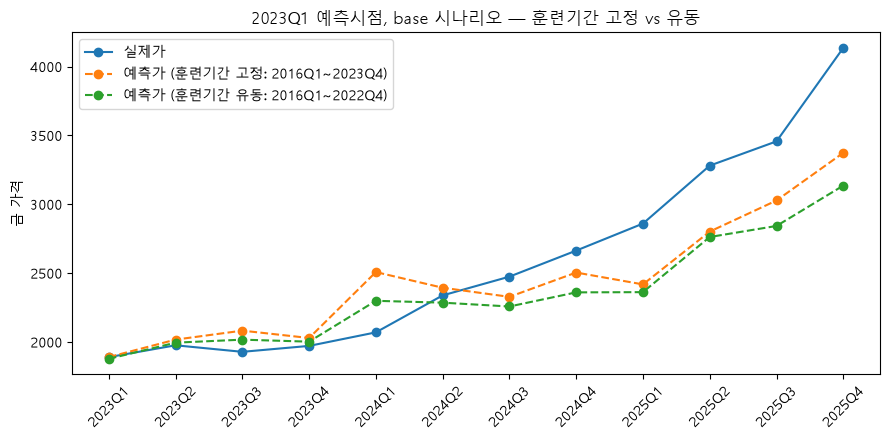

In [5]:
plt.figure(figsize=(9, 4.5))
plt.plot(merged["quarter"], merged["실제가"], marker="o", label="실제가")
plt.plot(merged["quarter"], merged["예측가(고정훈련)"], marker="o", linestyle="--",
         label="예측가 (훈련기간 고정: 2016Q1~2023Q4)")
plt.plot(merged["quarter"], merged["예측가(유동훈련)"], marker="o", linestyle="--",
         label="예측가 (훈련기간 유동: 2016Q1~2022Q4)")
plt.title("2023Q1 예측시점, base 시나리오 — 훈련기간 고정 vs 유동")
plt.ylabel("금 가격")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

### 예측시점 2024Q1

24Q1은 유동 훈련기간의 TRAIN_END(2023Q4)가 고정값과 완전히 같아서, 두 열이 **소수점까지 동일**하다 — 설계가 의도대로 동작한다는 sanity check.

In [6]:
target_quarters = [q for q in d["quarter"] if q >= "2024Q1" and q <= "2025Q4"]

fixed_df = predict_base_scenario(coef_fixed, mu_fixed, sd_fixed, mu_b4_fixed, sd_b4_fixed, "2024Q1", target_quarters)
dyn_df = predict_base_scenario(coef_dyn_24q1, mu_24q1, sd_24q1, mu_b4_24q1, sd_b4_24q1, "2024Q1", target_quarters)

merged = fixed_df.rename(columns={"예측가": "예측가(고정훈련)", "오차율(%)": "오차율%(고정훈련)"})
merged["예측가(유동훈련)"] = dyn_df["예측가"].values
merged["오차율%(유동훈련)"] = dyn_df["오차율(%)"].values
print(merged.to_string(index=False))

quarter         실제가   예측가(고정훈련)  오차율%(고정훈련)   예측가(유동훈련)  오차율%(유동훈련)
 2024Q1 2069.796032 2382.456088   15.105839 2382.456088   15.105839
 2024Q2 2338.175806 2297.842594   -1.724986 2297.842594   -1.724986
 2024Q3 2474.291538 2289.378605   -7.473369 2289.378605   -7.473369
 2024Q4 2663.376613 2466.654734   -7.386183 2466.654734   -7.386183
 2025Q1 2859.619048 2386.298972  -16.551858 2386.298972  -16.551858
 2025Q2 3280.352459 2779.740887  -15.260908 2779.740887  -15.260908
 2025Q3 3456.543846 2991.822954  -13.444669 2991.822954  -13.444669
 2025Q4 4135.235484 3331.386342  -19.439017 3331.386342  -19.439017


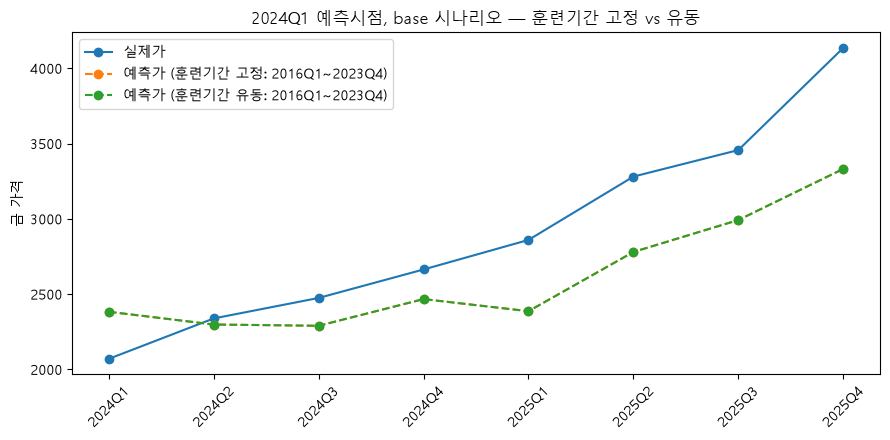

In [7]:
plt.figure(figsize=(9, 4.5))
plt.plot(merged["quarter"], merged["실제가"], marker="o", label="실제가")
plt.plot(merged["quarter"], merged["예측가(고정훈련)"], marker="o", linestyle="--",
         label="예측가 (훈련기간 고정: 2016Q1~2023Q4)")
plt.plot(merged["quarter"], merged["예측가(유동훈련)"], marker="o", linestyle="--",
         label="예측가 (훈련기간 유동: 2016Q1~2023Q4)")
plt.title("2024Q1 예측시점, base 시나리오 — 훈련기간 고정 vs 유동")
plt.ylabel("금 가격")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

### 예측시점 2025Q1

25Q1은 유동 훈련기간이 2024년 데이터(4개 분기)를 추가로 학습에 반영하므로, 고정 훈련기간과 다른 예측가가 나온다 — 실제로 오차율이 고정훈련 -14.44%~-8.24%, 유동훈련 -9.85%~-2.79%로, 유동훈련 쪽이 4개 분기 전부 실제가에 더 가깝다.

In [8]:
target_quarters = [q for q in d["quarter"] if q >= "2025Q1" and q <= "2025Q4"]

fixed_df = predict_base_scenario(coef_fixed, mu_fixed, sd_fixed, mu_b4_fixed, sd_b4_fixed, "2025Q1", target_quarters)
dyn_df = predict_base_scenario(coef_dyn_25q1, mu_25q1, sd_25q1, mu_b4_25q1, sd_b4_25q1, "2025Q1", target_quarters)

merged = fixed_df.rename(columns={"예측가": "예측가(고정훈련)", "오차율(%)": "오차율%(고정훈련)"})
merged["예측가(유동훈련)"] = dyn_df["예측가"].values
merged["오차율%(유동훈련)"] = dyn_df["오차율(%)"].values
print(merged.to_string(index=False))

quarter         실제가   예측가(고정훈련)  오차율%(고정훈련)   예측가(유동훈련)  오차율%(유동훈련)
 2025Q1 2859.619048 2560.353959  -10.465208 2674.571864   -6.471043
 2025Q2 3280.352459 2955.947160   -9.889343 3082.850344   -6.020759
 2025Q3 3456.543846 3171.883649   -8.235400 3360.132340   -2.789246
 2025Q4 4135.235484 3538.286571  -14.435669 3727.837004   -9.851881


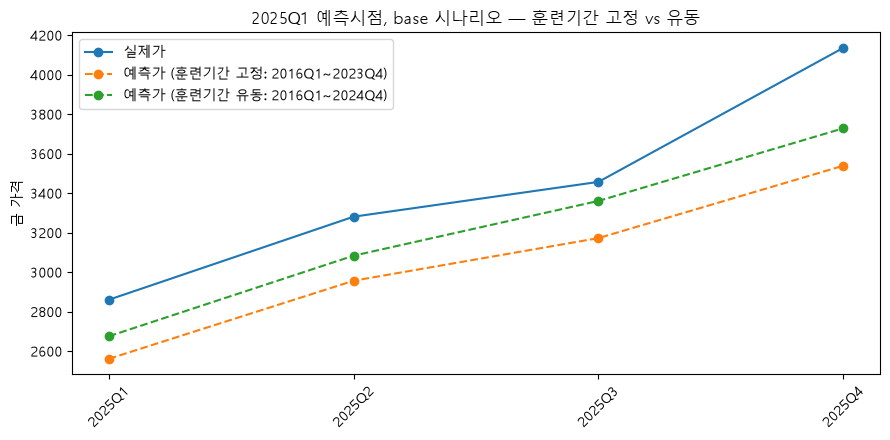

In [9]:
plt.figure(figsize=(9, 4.5))
plt.plot(merged["quarter"], merged["실제가"], marker="o", label="실제가")
plt.plot(merged["quarter"], merged["예측가(고정훈련)"], marker="o", linestyle="--",
         label="예측가 (훈련기간 고정: 2016Q1~2023Q4)")
plt.plot(merged["quarter"], merged["예측가(유동훈련)"], marker="o", linestyle="--",
         label="예측가 (훈련기간 유동: 2016Q1~2024Q4)")
plt.title("2025Q1 예측시점, base 시나리오 — 훈련기간 고정 vs 유동")
plt.ylabel("금 가격")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

## 계수 자체 비교 (2024Q4 시점, 학습 데이터 범위만 다름)

같은 "2024Q4"라는 분기를 가리키는 계수인데, 그 계수를 뽑아낸 모델이 2023Q4까지만 학습했는지
2024Q4까지 학습했는지에 따라 값이 달라지는지 직접 확인한다.

In [10]:
row_fixed_2024q4 = coef_fixed.loc[coef_fixed["quarter"] == "2024Q4"].iloc[0]
row_dyn_2024q4 = coef_dyn_25q1.loc[coef_dyn_25q1["quarter"] == "2024Q4"].iloc[0]
compare_df = pd.DataFrame({
    "고정훈련(2016Q1~2023Q4) 기준 2024Q4 계수": row_fixed_2024q4,
    "유동훈련(2016Q1~2024Q4) 기준 2024Q4 계수": row_dyn_2024q4,
})
print(compare_df.to_string())

        고정훈련(2016Q1~2023Q4) 기준 2024Q4 계수 유동훈련(2016Q1~2024Q4) 기준 2024Q4 계수
quarter                           2024Q4                           2024Q4
qdate                2024-10-01 00:00:00              2024-10-01 00:00:00
const                           0.069201                         0.082973
X1_l1                           0.017996                         0.016686
X2                             -0.111101                        -0.057108
X3_l1                           0.003296                         0.037802
X4_z                           -0.114427                        -0.016567
X5_l1                           0.008952                         0.020978
X6_l1                          -0.038175                        -0.070678


## 결론

**훈련기간 하드코딩의 룩어헤드 효과를 확인할 수 있는 사례는 23Q1이다 — 다만 그 크기는 계수 추출 인덱스 버그가 있던 이전 계산보다 약하다.**

고정 훈련기간(2016Q1~2023Q4)은 예측 대상인 2023년 데이터를 이미 학습에 포함하고 있다 — 즉 23Q1을 "예측"한다면서 사실은 그 해가 실제로 어떻게 흘러갔는지 모델이 이미 아는 상태로 계산하는 셈이다. 인덱스를 고친 뒤 다시 계산한 결과는 다음과 같다.

| 분기 | 고정훈련(룩어헤드 있음) 오차율 | 유동훈련(2022Q4까지만 학습) 오차율 |
|---|---|---|
| 2023Q1 | +0.02% | **-0.66%** |
| 2023Q2 | +2.08% | **+0.96%** |
| 2023Q3 | +7.98% | **+4.58%** |
| 2023Q4 | +2.91% | **+1.56%** |

평균 절대오차는 고정훈련 3.25%, 유동훈련 1.94%로, 유동훈련이 대체로 더 정확하다 — 다만 2023Q1 개별 분기만 보면 고정훈련(+0.02%)이 유동훈련(-0.66%)보다 오히려 근소하게 더 정확해서, 이전 버전에서 보였던 "고정훈련은 항상 크게 과대예측, 유동훈련은 항상 훨씬 정직"이라는 대비만큼 극적이진 않다. 그래도 3개 분기(23Q2~23Q4)에서 일관되게 유동훈련의 오차가 더 작고, 두 방식의 유일한 차이가 "훈련기간에 예측 대상 연도가 포함되는지 여부"뿐이라는 점을 보면, 방향성 자체는 여전히 룩어헤드 쪽이 불리하다는 결론을 뒷받침한다.

(참고로 24Q1은 유동 훈련기간의 TRAIN_END가 고정값과 우연히 일치해 두 방식이 완전히 같은 결과를 내고, 25Q1은 고정훈련 -14.44%~-8.24%, 유동훈련 -9.85%~-2.79%로 유동훈련 쪽이 실제가에 더 가까웠다 — 학습에 더 최근 데이터가 반영될수록 유동훈련이 유리한 경향은 유지된다.)